# 03 · Đánh giá và so sánh

**Khoa** · Chạy sau notebook 02. Các thuật toán dùng cùng mẫu, 8 biến và chuẩn hóa của Đức.

## 1. Giới thiệu mục tiêu đánh giá

So sánh DBSCAN, K-Means, Agglomerative và GMM bằng ba chỉ số cùng độ phủ. Không chọn thuật toán chỉ từ một điểm số.

In [1]:
from pathlib import Path
import hashlib
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

ROOT = Path.cwd().resolve()
while not (ROOT / "du_lieu").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Hãy mở notebook trong repo DBSCAN.")
    ROOT = ROOT.parent
OUT = ROOT / "ket_qua_chung/danh_gia"
PROFILES = ROOT / "ket_qua_chung/ho_so_cum"
NOISE = ROOT / "ket_qua_chung/phan_tich_nhieu"
FIG = ROOT / "Khoa/bieu_do"
for folder in [OUT, PROFILES, NOISE, FIG]:
    folder.mkdir(parents=True, exist_ok=True)
KEYS = ["country", "year"]
SEED = 42
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 110})

## 2. Chuẩn bị dữ liệu và nhãn phân cụm

In [2]:
clean_path = ROOT / "du_lieu/du_lieu_sach/wdi_clean.csv"
scaled_path = ROOT / "du_lieu/du_lieu_chuan_hoa/wdi_scaled.csv"
meta = json.loads((ROOT / "du_lieu/du_lieu_chuan_hoa/preprocessing_metadata.json").read_text())
params = json.loads((ROOT / "ket_qua_chung/dbscan/tham_so_da_chon.json").read_text())
assert params["fit_scope"] == "global_panel", "Notebook này đánh giá mô hình panel."
assert hashlib.sha256(clean_path.read_bytes()).hexdigest() == meta["outputs"]["clean_sha256"]
assert hashlib.sha256(scaled_path.read_bytes()).hexdigest() == meta["outputs"]["scaled_sha256"]
features = meta["feature_columns"]
clean = pd.read_csv(clean_path).sort_values(KEYS).reset_index(drop=True)
scaled = pd.read_csv(scaled_path).sort_values(KEYS).reset_index(drop=True)
labels = pd.read_csv(ROOT / "ket_qua_chung/dbscan/dbscan_labels.csv").sort_values(KEYS).reset_index(drop=True)
for table in [clean, scaled, labels]:
    assert not table.duplicated(KEYS).any() and not table[KEYS].isna().any().any()
assert clean[KEYS].equals(scaled[KEYS]) and labels[KEYS].equals(scaled[KEYS])
assert np.array_equal(labels.cluster.eq(-1), labels.point_type.eq("noise"))
assert clean.is_aggregate.eq(0).all()
X = scaled[features].to_numpy(dtype=float)
assert np.isfinite(X).all()
all_labels = {"DBSCAN": labels.cluster.to_numpy()}
config = {"DBSCAN": {"eps": params["eps"], "min_samples": params["min_samples"]}}
selection_rows = []
dictionary = pd.read_csv(ROOT / "du_lieu/tu_dien_chi_tieu.csv")
names = dict(zip(dictionary.indicator, dictionary.name_vi))
print(f"Đủ đầu vào: {len(X)} quan sát, {len(features)} biến, khóa khớp một-một.")

Đủ đầu vào: 2315 quan sát, 8 biến, khóa khớp một-một.


## 3. Triển khai K-Means

Thử k=2..10, mỗi k khởi tạo 10 lần; chọn Silhouette lớn nhất trên toàn mẫu.

In [3]:
kmeans_candidates = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    y = model.fit_predict(X)
    score = silhouette_score(X, y)
    kmeans_candidates.append((score, k, y))
    selection_rows.append({"algorithm": "K-Means", "k": k, "criterion": "silhouette", "value": score})
best_score, best_k, best_labels = max(kmeans_candidates, key=lambda row: row[0])
all_labels["K-Means"] = best_labels
config["K-Means"] = {"n_clusters": best_k, "n_init": 10, "random_state": SEED}
print("K-Means: k =", best_k, "| Silhouette =", round(best_score, 4))

K-Means: k = 5 | Silhouette = 0.1836


## 4. Triển khai Agglomerative Clustering

Dùng Ward và khoảng cách Euclidean, thử k=2..10.

In [4]:
agg_candidates = []
for k in range(2, 11):
    y = AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean").fit_predict(X)
    score = silhouette_score(X, y)
    agg_candidates.append((score, k, y))
    selection_rows.append({"algorithm": "Agglomerative", "k": k, "criterion": "silhouette", "value": score})
best_score, best_k, best_labels = max(agg_candidates, key=lambda row: row[0])
all_labels["Agglomerative"] = best_labels
config["Agglomerative"] = {"n_clusters": best_k, "linkage": "ward", "metric": "euclidean"}
print("Agglomerative: k =", best_k, "| Silhouette =", round(best_score, 4))

Agglomerative: k = 2 | Silhouette = 0.1751


## 5. Triển khai Gaussian Mixture Model

Thử 4 dạng covariance, k=2..10, mỗi cấu hình khởi tạo 3 lần. Chọn BIC thấp nhất trong các mô hình hội tụ.

In [5]:
gmm_candidates = []
for covariance in ["full", "tied", "diag", "spherical"]:
    for k in range(2, 11):
        model = GaussianMixture(n_components=k, covariance_type=covariance, n_init=3,
                                max_iter=500, reg_covar=1e-6, random_state=SEED)
        y = model.fit_predict(X)
        bic = float(model.bic(X))
        selection_rows.append({"algorithm": "GMM", "k": k, "covariance": covariance,
                               "criterion": "BIC", "value": bic, "converged": bool(model.converged_)})
        if model.converged_:
            gmm_candidates.append((bic, k, covariance, y))
if not gmm_candidates:
    raise RuntimeError("Không có GMM hội tụ; chưa thể so sánh.")
best_bic, best_k, best_covariance, best_labels = min(gmm_candidates, key=lambda row: row[0])
all_labels["GMM"] = best_labels
config["GMM"] = {"n_components": best_k, "covariance_type": best_covariance,
                 "n_init": 3, "random_state": SEED, "max_iter": 500, "reg_covar": 1e-6}
print("GMM:", best_k, best_covariance, "| BIC =", round(best_bic, 2))

GMM: 10 full | BIC = 36121.21


## 6. Đánh giá bằng Silhouette Score

Cao hơn thường tốt hơn trên cùng tập mẫu. Chỉ tính khi có từ 2 nhãn tới ít hơn số điểm; loại noise của DBSCAN khỏi phép tính chính.

In [6]:
def cluster_scores(points, y):
    if not 2 <= len(np.unique(y)) < len(y):
        return {"silhouette": np.nan, "davies_bouldin": np.nan,
                "calinski_harabasz": np.nan, "metric_note": "N/A: số nhãn không hợp lệ"}
    return {"silhouette": float(silhouette_score(points, y)),
            "davies_bouldin": float(davies_bouldin_score(points, y)),
            "calinski_harabasz": float(calinski_harabasz_score(points, y)),
            "metric_note": "Hợp lệ"}

for y in [np.array([]), np.array([0, 0, 0]), np.array([0, 1, 2])]:
    assert np.isnan(cluster_scores(np.zeros((len(y), 2)), y)["silhouette"])
print("Đạt kiểm thử chỉ số khi mẫu rỗng, một cụm và mỗi điểm một nhãn.")

Đạt kiểm thử chỉ số khi mẫu rỗng, một cụm và mỗi điểm một nhãn.


## 7. Đánh giá bằng Davies-Bouldin Index

Thấp hơn thường tốt hơn: so độ phân tán trong cụm với khoảng cách giữa cụm.

## 8. Đánh giá bằng Calinski-Harabasz Index

Cao hơn thường tốt hơn trên cùng tập mẫu: so độ phân tán giữa cụm với trong cụm.

## 9. So sánh kết quả các thuật toán

Bảng có hai phạm vi: theo chính sách từng thuật toán và **cùng tập con non-noise của DBSCAN**. Giữ nhãn đã fit toàn mẫu khi đánh giá tập con, không fit lại. Không so trực tiếp điểm số của hai tập mẫu khác nhau.

In [7]:
non_noise = all_labels["DBSCAN"] >= 0
rows = []
for algorithm, y in all_labels.items():
    policy = non_noise if algorithm == "DBSCAN" else np.ones(len(X), dtype=bool)
    for evaluation_set, mask in [("algorithm_policy", policy), ("dbscan_non_noise_common_subset", non_noise)]:
        rows.append({"algorithm": algorithm, "evaluation_set": evaluation_set, "fit_scope": "global_panel",
                     "n_input": len(X), "n_evaluated": int(mask.sum()), "coverage": float(mask.mean()),
                     "n_clusters": len(np.unique(y[mask])), "noise_ratio": float((y < 0).mean()),
                     **cluster_scores(X[mask], y[mask])})
comparison = pd.DataFrame(rows)
comparison.to_csv(OUT / "so_sanh_thuat_toan.csv", index=False)
pd.DataFrame(selection_rows).to_csv(OUT / "lua_chon_mo_hinh_doi_chung.csv", index=False)
baseline_labels = labels.copy()
for algorithm in ["K-Means", "Agglomerative", "GMM"]:
    baseline_labels[algorithm] = all_labels[algorithm]
baseline_labels.to_csv(OUT / "nhan_thuat_toan_doi_chung.csv", index=False)
(OUT / "cau_hinh_thuat_toan_doi_chung.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")
display(comparison.round(4))

,algorithm,evaluation_set,fit_scope,n_input,n_evaluated,coverage,n_clusters,noise_ratio,silhouette,davies_bouldin,calinski_harabasz,metric_note
0,DBSCAN,algorithm_policy,global_panel,2315,759,0.3279,4,0.6721,0.1889,0.9772,106.8101,Hợp lệ
1,DBSCAN,dbscan_non_noise_common_subset,global_panel,2315,759,0.3279,4,0.6721,0.1889,0.9772,106.8101,Hợp lệ
2,K-Means,algorithm_policy,global_panel,2315,2315,1.0000,5,0.0000,0.1836,1.4666,330.7703,Hợp lệ
3,K-Means,dbscan_non_noise_common_subset,global_panel,2315,759,0.3279,3,0.0000,0.2589,1.2590,201.7165,Hợp lệ
4,Agglomerative,algorithm_policy,global_panel,2315,2315,1.0000,2,0.0000,0.1751,2.2240,326.5904,Hợp lệ
5,Agglomerative,dbscan_non_noise_common_subset,global_panel,2315,759,0.3279,2,0.0000,0.2679,1.3170,180.1887,Hợp lệ
6,GMM,algorithm_policy,global_panel,2315,2315,1.0000,10,0.0000,0.0444,2.9130,109.5944,Hợp lệ
7,GMM,dbscan_non_noise_common_subset,global_panel,2315,759,0.3279,8,0.0000,0.0601,2.0028,106.5952,Hợp lệ


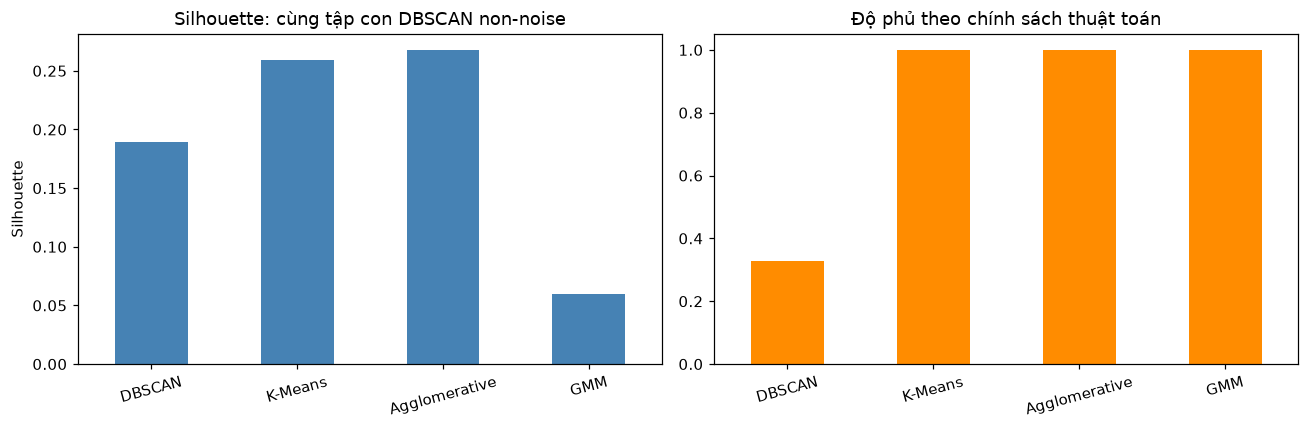

In [8]:
common = comparison[comparison.evaluation_set == "dbscan_non_noise_common_subset"].set_index("algorithm")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
common.silhouette.plot.bar(ax=axes[0], color="steelblue", rot=15)
for i, value in enumerate(common.silhouette):
    if pd.isna(value):
        axes[0].text(i, 0, "N/A", ha="center", va="bottom")
axes[0].set(title="Silhouette: cùng tập con DBSCAN non-noise", ylabel="Silhouette", xlabel="")
comparison[comparison.evaluation_set == "algorithm_policy"].set_index("algorithm").coverage.plot.bar(
    ax=axes[1], color="darkorange", rot=15)
axes[1].set(title="Độ phủ theo chính sách thuật toán", ylim=(0, 1.05), xlabel="")
fig.tight_layout(); fig.savefig(FIG / "02_so_sanh_chi_so_va_do_phu.png"); plt.show()

## 10. Trực quan hóa PCA 2D

Dùng chung hệ trục. PCA chỉ để vẽ; mô hình vẫn fit trên 8 biến.

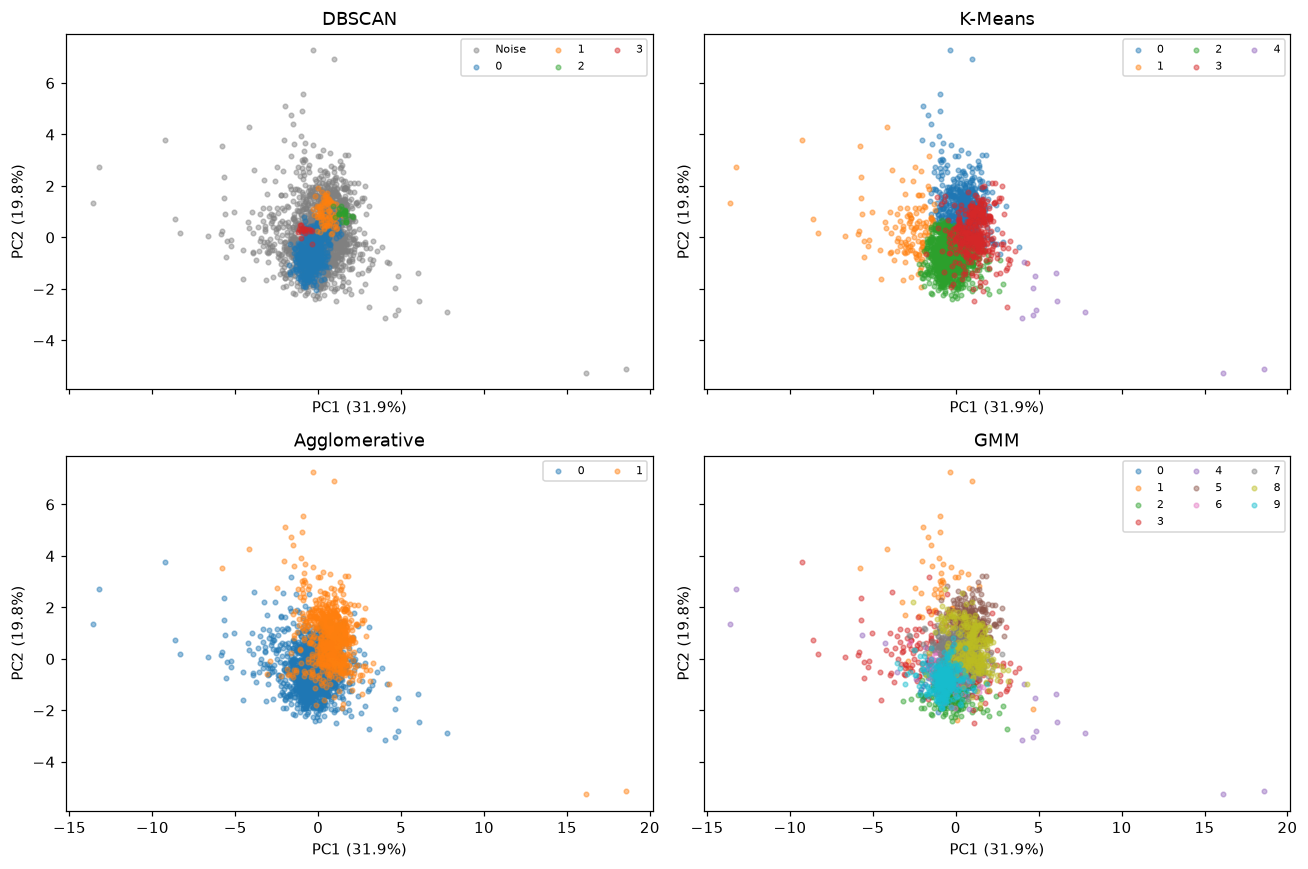

295

In [9]:
pca = PCA(n_components=2)
coordinates = pca.fit_transform(X)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, (algorithm, y) in zip(axes.flat, all_labels.items()):
    for cluster in np.unique(y):
        mask = y == cluster
        ax.scatter(coordinates[mask, 0], coordinates[mask, 1], s=9, alpha=0.45,
                   color="gray" if cluster == -1 else None,
                   label="Noise" if cluster == -1 else str(cluster))
    ax.set(title=algorithm, xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
           ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
    ax.legend(fontsize=7, ncol=3)
fig.tight_layout(); fig.savefig(FIG / "01_pca_so_sanh_thuat_toan.png"); plt.show()
(OUT / "pca_metadata.json").write_text(json.dumps({"feature_columns": features,
    "explained_variance_ratio": pca.explained_variance_ratio_.tolist()}, indent=2) + "\n")

## 11. Phân tích đặc điểm từng cụm

Thống kê ở đơn vị gốc. Quan sát đại diện là những điểm gần trung vị cụm trong không gian chuẩn hóa, không phải xếp hạng nền kinh tế.

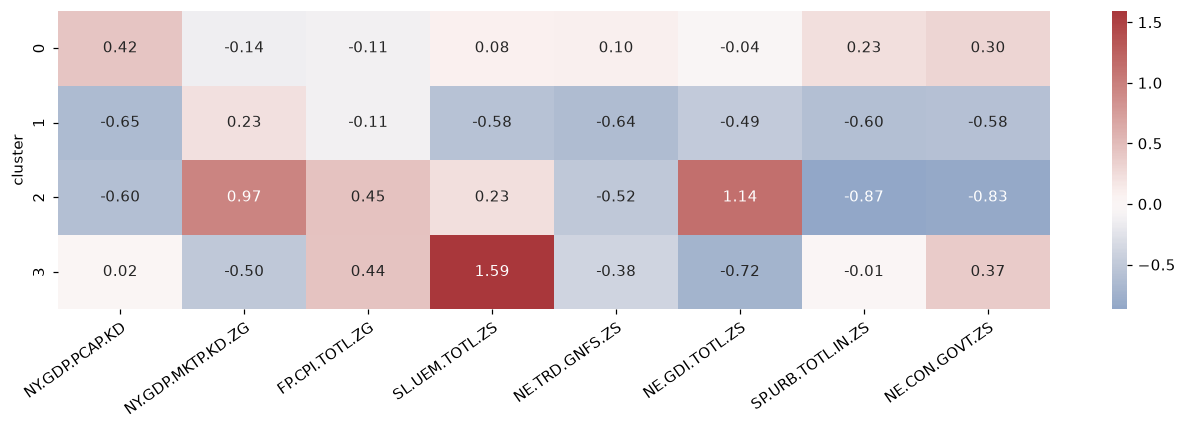

,n_samples,n_countries
cluster,,
0,628,80
1,89,15
2,24,4
3,18,3


In [10]:
profile_data = clean.merge(labels, on=KEYS, validate="one_to_one")
clustered = profile_data[profile_data.cluster >= 0]
profile = clustered.groupby("cluster")[features].agg(["mean", "median", "std"])
profile.columns = [feature + "__" + stat for feature, stat in profile.columns]
profile.to_csv(PROFILES / "ho_so_cum_dbscan.csv")
profile_long = clustered.melt(id_vars=["cluster"], value_vars=features,
                              var_name="feature", value_name="value")
profile_long = profile_long.groupby(["cluster", "feature"]).value.agg(["count", "mean", "median", "std"])
profile_long.to_csv(PROFILES / "ho_so_cum_dbscan_dang_dai.csv")
representatives = []
for cluster in sorted(clustered.cluster.unique()):
    indices = np.flatnonzero(labels.cluster.to_numpy() == cluster)
    distances = np.linalg.norm(X[indices] - np.median(X[indices], axis=0), axis=1)
    chosen = indices[np.argsort(distances)[:5]]
    representatives.append(profile_data.iloc[chosen][KEYS + ["country_name", "cluster"]])
pd.concat(representatives, ignore_index=True).to_csv(PROFILES / "quan_sat_dai_dien_cum.csv", index=False)
heatmap = scaled[features].assign(cluster=labels.cluster).query("cluster >= 0").groupby("cluster").median()
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(heatmap, cmap="vlag", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_xticklabels(features, rotation=35, ha="right", rotation_mode="anchor")
fig.tight_layout(); fig.savefig(FIG / "03_ho_so_cum_dbscan.png"); plt.show()
display(clustered.groupby("cluster").agg(n_samples=("country", "size"), n_countries=("country", "nunique")))

## 12. Phân tích các điểm nhiễu

So noise với trung vị/IQR của non-noise, lưu 3 biến lệch nhiều nhất. Đây là dấu hiệu thống kê, chưa chứng minh nguyên nhân kinh tế.

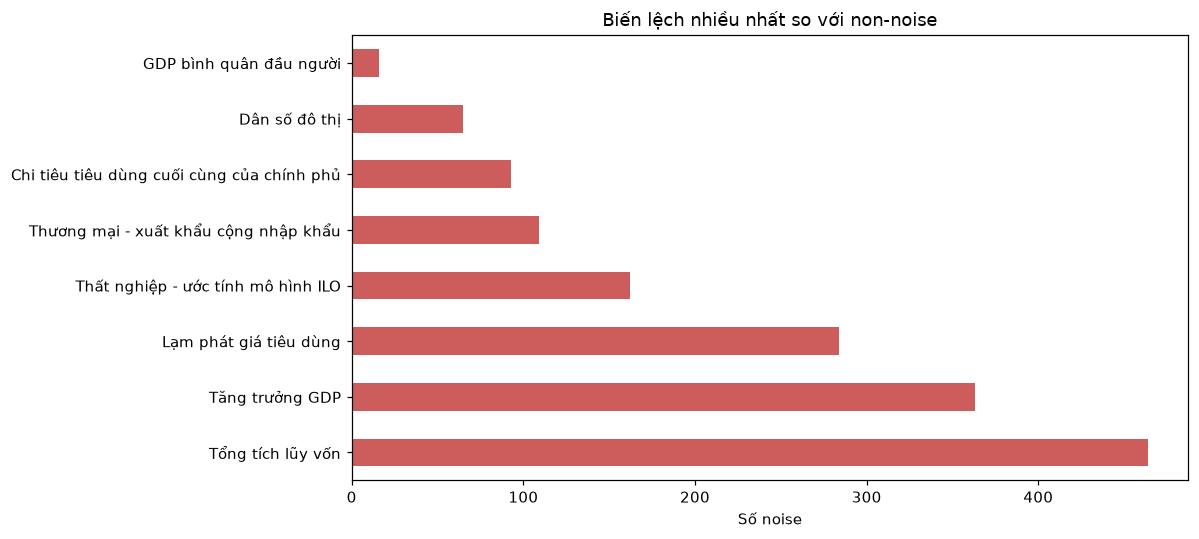

In [11]:
reference = scaled.loc[non_noise, features]
iqr = reference.quantile(0.75) - reference.quantile(0.25)
assert (iqr > 0).all(), "Không thể chuẩn hóa độ lệch khi IQR bằng 0."
deviation = ((scaled.loc[~non_noise, features] - reference.median()) / iqr).abs()
noise = profile_data.loc[~non_noise].copy()
top_features, top_values = [], []
for _, row in deviation.iterrows():
    top = row.nlargest(3)
    top_features.append(top.index.tolist())
    top_values.append(top.tolist())
for rank in range(3):
    noise[f"top_deviation_feature_{rank + 1}"] = [v[rank] for v in top_features]
    noise[f"absolute_iqr_deviation_{rank + 1}"] = [v[rank] for v in top_values]
noise["top_deviation_feature_name_1"] = noise.top_deviation_feature_1.map(names)
noise.to_csv(NOISE / "danh_sach_va_dac_trung_noise.csv", index=False)
noise_summary = noise.top_deviation_feature_name_1.value_counts().rename("n_noise")
noise_summary.to_csv(NOISE / "tong_hop_noise_theo_dac_trung.csv")
fig, ax = plt.subplots(figsize=(11, 5))
noise_summary.plot.barh(ax=ax, color="indianred")
ax.set(xlabel="Số noise", ylabel="", title="Biến lệch nhiều nhất so với non-noise")
fig.tight_layout(); fig.savefig(FIG / "04_noise_theo_dac_trung_khac_biet.png"); plt.show()

## 13. Nhận xét và kết luận

Đọc cả 3 chỉ số, độ phủ và độ nhạy. Chỉ số nội bộ có thể ưu tiên một vài dạng hình học; PCA mất thông tin và các năm cùng quốc gia không độc lập.

In [12]:
display(comparison[comparison.evaluation_set == "dbscan_non_noise_common_subset"].round(4))
assert len(baseline_labels) == len(clean) and baseline_labels[KEYS].equals(clean[KEYS])
assert len(noise) == int((labels.cluster < 0).sum())
REPORT = ROOT / "ket_qua_chung/bieu_do_bao_cao"
REPORT.mkdir(parents=True, exist_ok=True)
for path in FIG.glob("*.png"):
    (REPORT / ("khoa_" + path.name)).write_bytes(path.read_bytes())
print(f"Đã xuất bảng so sánh, hồ sơ cụm và {len(noise)} quan sát noise.")

,algorithm,evaluation_set,fit_scope,n_input,n_evaluated,coverage,n_clusters,noise_ratio,silhouette,davies_bouldin,calinski_harabasz,metric_note
1,DBSCAN,dbscan_non_noise_common_subset,global_panel,2315,759,0.3279,4,0.6721,0.1889,0.9772,106.8101,Hợp lệ
3,K-Means,dbscan_non_noise_common_subset,global_panel,2315,759,0.3279,3,0.0000,0.2589,1.2590,201.7165,Hợp lệ
5,Agglomerative,dbscan_non_noise_common_subset,global_panel,2315,759,0.3279,2,0.0000,0.2679,1.3170,180.1887,Hợp lệ
7,GMM,dbscan_non_noise_common_subset,global_panel,2315,759,0.3279,8,0.0000,0.0601,2.0028,106.5952,Hợp lệ


Đã xuất bảng so sánh, hồ sơ cụm và 1556 quan sát noise.
